# IntentCart: Online Purchase Intention
ES 335 course project. This notebook walks through the data checks and EDA, then
loads the outputs of `src/run_all.py` and **independently re-fits the selected
models** from their saved hyper-parameters to confirm the reported test numbers.

Run `python src/run_all.py` first (it writes `results/`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import intentcart as si
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
df = si.load_data()
print(df.shape); df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


## 1. Data quality
One row = one browsing session. Checks below learn nothing, so they are safe to run on the full table.

In [2]:
q = si.quality_report(df); q

{'n_rows': 12330,
 'n_features': 17,
 'n_positive': 1908,
 'positive_rate': 0.15474452554744525,
 'missing_values': 0,
 'duplicate_rows_extra_copies': 125,
 'rows_in_duplicate_groups': 201,
 'duplicate_rows_all_nonpurchase': True,
 'duplicate_rows_all_single_page_bounce': True,
 'negative_values': {},
 'months_present': ['Feb',
  'Mar',
  'May',
  'June',
  'Jul',
  'Aug',
  'Sep',
  'Oct',
  'Nov',
  'Dec'],
 'months_missing': ['Jan', 'Apr']}

In [3]:
dups = df[df.duplicated(keep=False)]
print('extra duplicate copies:', df.duplicated().sum())
dups[['ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','Revenue']].describe().T

extra duplicate copies: 125


,count,mean,std,min,25%,50%,75%,max
ProductRelated,201.0,1.059701,0.237525,1.0,1.0,1.0,1.0,2.0
ProductRelated_Duration,201.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
BounceRates,201.0,0.200000,0.000000,0.2,0.2,0.2,0.2,0.2
ExitRates,201.0,0.200000,0.000000,0.2,0.2,0.2,0.2,0.2
PageValues,201.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
Revenue,201.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


All duplicates are one-page bounce sessions with zero duration and no purchase. With so few
distinct values, different real visitors produce identical rows, so we **keep** them (they are
real traffic) and check in `extra_experiments.json` that removing them changes nothing material.

## 2. Target and key variables

Revenue
0    10422
1     1908
Name: count, dtype: int64 0.1547


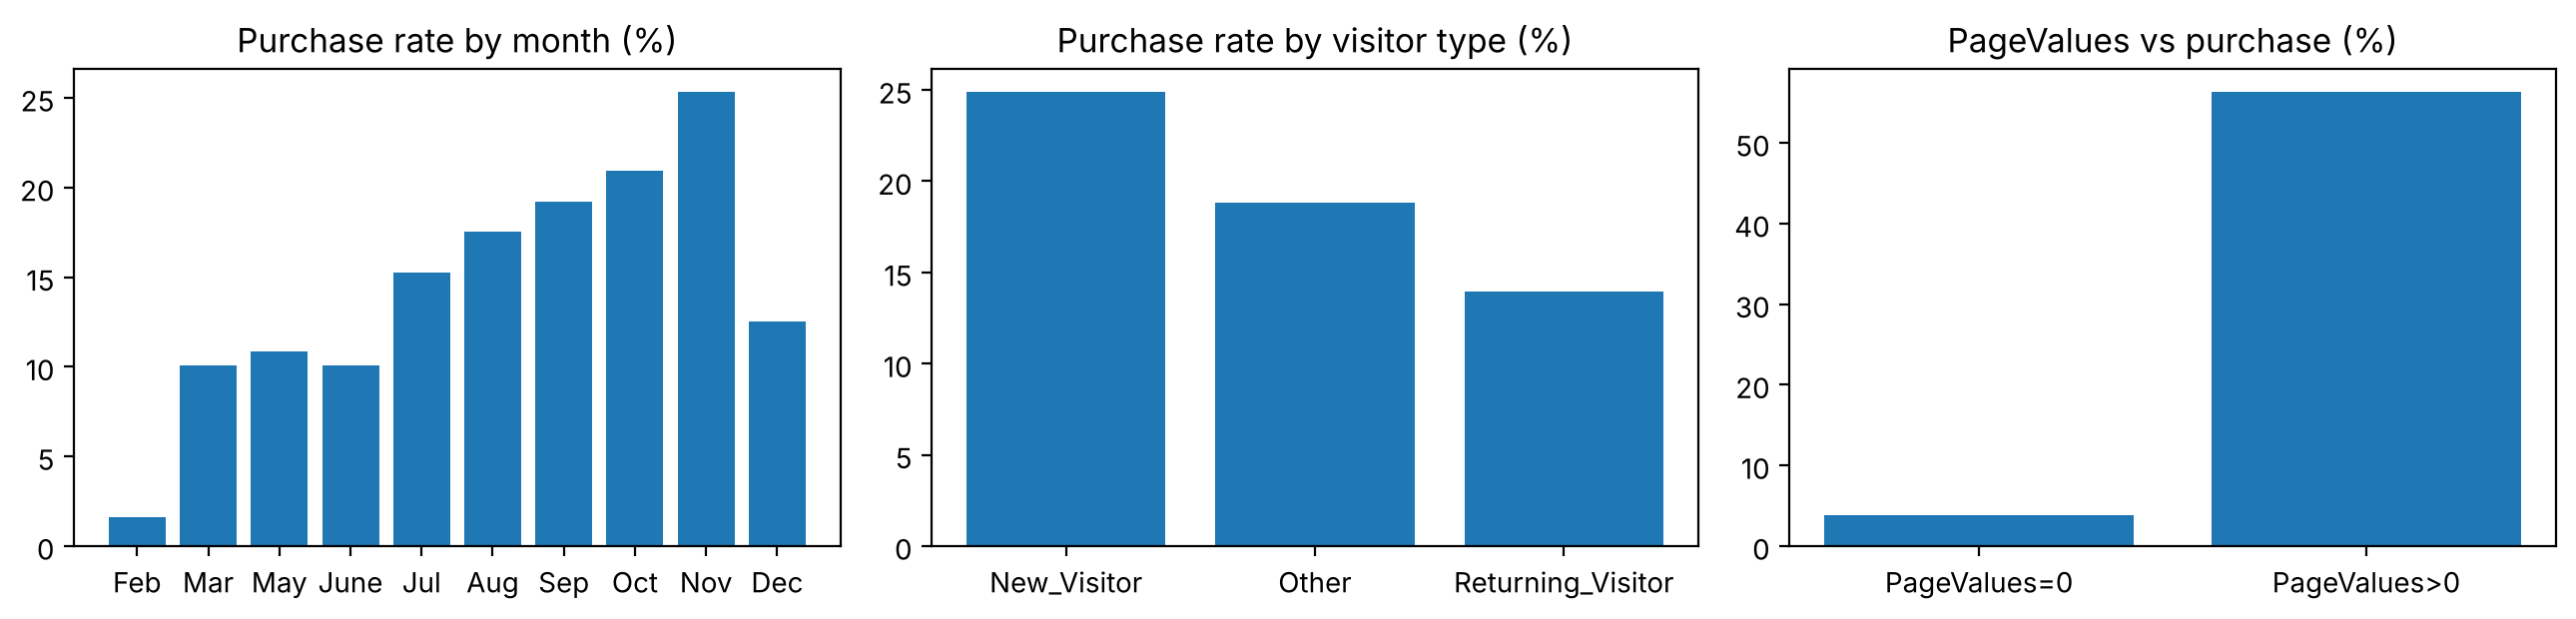

In [4]:
print(df.Revenue.value_counts(), df.Revenue.mean().round(4))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
r = df.groupby('Month', sort=False).Revenue.mean().reindex(si.MONTH_ORDER)
ax[0].bar(r.index, r.values*100); ax[0].set_title('Purchase rate by month (%)')
v = df.groupby('VisitorType').Revenue.mean()
ax[1].bar(v.index, v.values*100); ax[1].set_title('Purchase rate by visitor type (%)')
pv = df.groupby(df.PageValues > 0).Revenue.mean()
ax[2].bar(['PageValues=0','PageValues>0'], pv.values*100); ax[2].set_title('PageValues vs purchase (%)')
plt.tight_layout()

In [5]:
num = si.COUNT_DURATION + si.RATES + si.PAGE_VALUES
pd.DataFrame({'skew': df[num].skew().round(2), 'median_no_buy': df[df.Revenue==0][num].median(),
              'median_buy': df[df.Revenue==1][num].median(), 'max': df[num].max()})

,skew,median_no_buy,median_buy,max
Administrative,1.96,0.000000,2.000000,27.000000
Administrative_Duration,5.62,0.000000,52.366667,3398.750000
Informational,4.04,0.000000,0.000000,24.000000
Informational_Duration,7.58,0.000000,0.000000,2549.375000
ProductRelated,4.34,16.000000,29.000000,705.000000
ProductRelated_Duration,7.26,510.190000,1109.906250,63973.522230
BounceRates,2.95,0.004255,0.000000,0.200000
ExitRates,2.15,0.028571,0.016000,0.200000
PageValues,6.38,0.000000,16.758134,361.763742


Strong right skew in counts/durations motivates `log1p` before scaling for logistic regression.
`PageValues` is 0 for ~78% of sessions and nearly separates the classes; because Google
Analytics derives it from revenue on the same pages, we treat it as a leakage risk (setting A vs B).

## 3. Split (fixed, stratified 70/15/15, seed 42)

In [6]:
split = pd.read_csv(ROOT/'results/splits.csv')
assert (split.split.values == si.make_split(df).values).all()   # split is reproducible
split.groupby('split').Revenue.agg(['size','sum','mean'])

,size,sum,mean
split,,,
test,1850,286,0.154595
train,8631,1336,0.154791
val,1849,286,0.154678


## 4. Validation results (model selection)

In [7]:
sel = pd.read_csv(ROOT/'results/model_selection.csv')
sel[['setting','model','n_configs','params','val_pr_auc','val_f1','val_threshold','selected']].round(3)

,setting,model,n_configs,params,val_pr_auc,val_f1,val_threshold,selected
0,A,majority,1,{},0.155,0.000,0.500,False
1,A,stump,1,{},0.440,0.624,0.580,False
2,A,logreg,8,"{""C"": 0.1, ""class_weight"": null}",0.666,0.642,0.352,False
3,A,tree,24,"{""max_depth"": 8, ""min_samples_leaf"": 50, ""clas...",0.668,0.622,0.651,False
4,A,forest,16,"{""max_depth"": null, ""min_samples_leaf"": 5, ""ma...",0.718,0.647,0.367,False
5,A,gboost,8,"{""learning_rate"": 0.03, ""max_leaf_nodes"": 15, ...",0.727,0.653,0.361,True
6,B,majority,1,{},0.155,0.000,0.500,False
7,B,stump,1,{},0.197,0.330,0.234,False
8,B,logreg,8,"{""C"": 0.1, ""class_weight"": null}",0.331,0.410,0.210,False
9,B,tree,24,"{""max_depth"": 8, ""min_samples_leaf"": 50, ""clas...",0.291,0.382,0.537,False


## 5. Test results (each tuned model scored once, at its validation threshold)

In [8]:
tr = pd.read_csv(ROOT/'results/test_results.csv')
tr[['setting','model','selected','test_pr_auc','ci_pr_auc','test_roc_auc','test_precision','test_recall','test_f1','test_accuracy']].round(3)

,setting,model,selected,test_pr_auc,ci_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,test_accuracy
0,A,majority,False,0.155,NaN,0.500,0.000,0.000,0.000,0.845
1,A,stump,False,0.474,"[0.42247080560806916, 0.5250665739243393]",0.837,0.561,0.787,0.655,0.872
2,A,logreg,False,0.655,"[0.5954867317033177, 0.7206269197040293]",0.915,0.643,0.661,0.652,0.891
3,A,tree,False,0.713,"[0.6609725613796981, 0.7637472181663199]",0.918,0.598,0.776,0.676,0.885
4,A,forest,False,0.731,"[0.6790991954036992, 0.7809654175088745]",0.926,0.660,0.692,0.676,0.897
5,A,gboost,True,0.743,"[0.6916832574489123, 0.7904976791875251]",0.933,0.650,0.703,0.676,0.896
6,B,majority,False,0.155,NaN,0.500,0.000,0.000,0.000,0.845
7,B,stump,False,0.213,"[0.1891680332629628, 0.2382354757638891]",0.652,0.227,0.804,0.355,0.548
8,B,logreg,False,0.345,"[0.2939013722113611, 0.41059899837832836]",0.753,0.308,0.577,0.402,0.735
9,B,tree,False,0.345,"[0.2907691843108185, 0.4033438034598741]",0.738,0.276,0.657,0.389,0.681


## 6. Independent re-fit check
Re-build the selected models from saved parameters, train on the train split only, and score on test.

In [9]:
from sklearn.metrics import average_precision_score
tr_df, te_df = df[split.split.values=='train'], df[split.split.values=='test']
for s in ['A','B']:
    row = sel[(sel.setting==s) & sel.selected].iloc[0]
    feats = si.features_for(s)
    pipe = si.build_model(row.model, json.loads(row.params), feats).fit(tr_df[feats], tr_df.Revenue)
    ap = average_precision_score(te_df.Revenue, pipe.predict_proba(te_df[feats])[:,1])
    rep = tr[(tr.setting==s)&(tr.model==row.model)].test_pr_auc.iloc[0]
    print(s, row.model, 'refit PR-AUC', round(ap,4), 'reported', round(rep,4))
    assert abs(ap-rep) < 1e-6

A gboost refit PR-AUC 0.7433 reported 0.7433


B gboost refit PR-AUC 0.3723 reported 0.3723


## 7. Extra experiments

In [10]:
ex = json.load(open(ROOT/'results/extra_experiments.json'))
print('5-fold CV on train+val (PR-AUC mean ± sd):')
for s in ['A','B']:
    print(s, {m: f"{v['mean']:.3f}±{v['sd']:.3f}" for m, v in ex['cv_trainval'][s].items()})
print('\nTemporal hold-out (train Feb-Sep, threshold on Oct, test Nov-Dec):')
print(json.dumps(ex['temporal'], indent=1)[:1500])
print('\nDeduplicated re-run (test PR-AUC):', ex['dedup'])
print('Ablation without BounceRates/ExitRates:', ex['ablation_no_rates'])

5-fold CV on train+val (PR-AUC mean ± sd):
A {'majority': '0.155±0.000', 'stump': '0.486±0.021', 'logreg': '0.693±0.034', 'tree': '0.707±0.034', 'forest': '0.749±0.031', 'gboost': '0.751±0.037'}
B {'majority': '0.155±0.000', 'stump': '0.217±0.004', 'logreg': '0.338±0.015', 'tree': '0.336±0.010', 'forest': '0.380±0.012', 'gboost': '0.366±0.008'}

Temporal hold-out (train Feb-Sep, threshold on Oct, test Nov-Dec):
{
 "train": {
  "months": "Feb-Sep",
  "n": 7056,
  "rate": 0.1158
 },
 "val": {
  "months": "Oct",
  "n": 549,
  "rate": 0.2095
 },
 "test": {
  "months": "Nov-Dec",
  "n": 4725,
  "rate": 0.2066
 },
 "results": {
  "A": {
   "stump": {
    "pr_auc": 0.4784,
    "threshold": 0.5662,
    "precision": 0.6284,
    "recall": 0.6445,
    "f1": 0.6363
   },
   "logreg": {
    "pr_auc": 0.6323,
    "threshold": 0.2839,
    "precision": 0.6662,
    "recall": 0.54,
    "f1": 0.5965
   },
   "forest": {
    "pr_auc": 0.6695,
    "threshold": 0.3055,
    "precision": 0.668,
    "recall": 

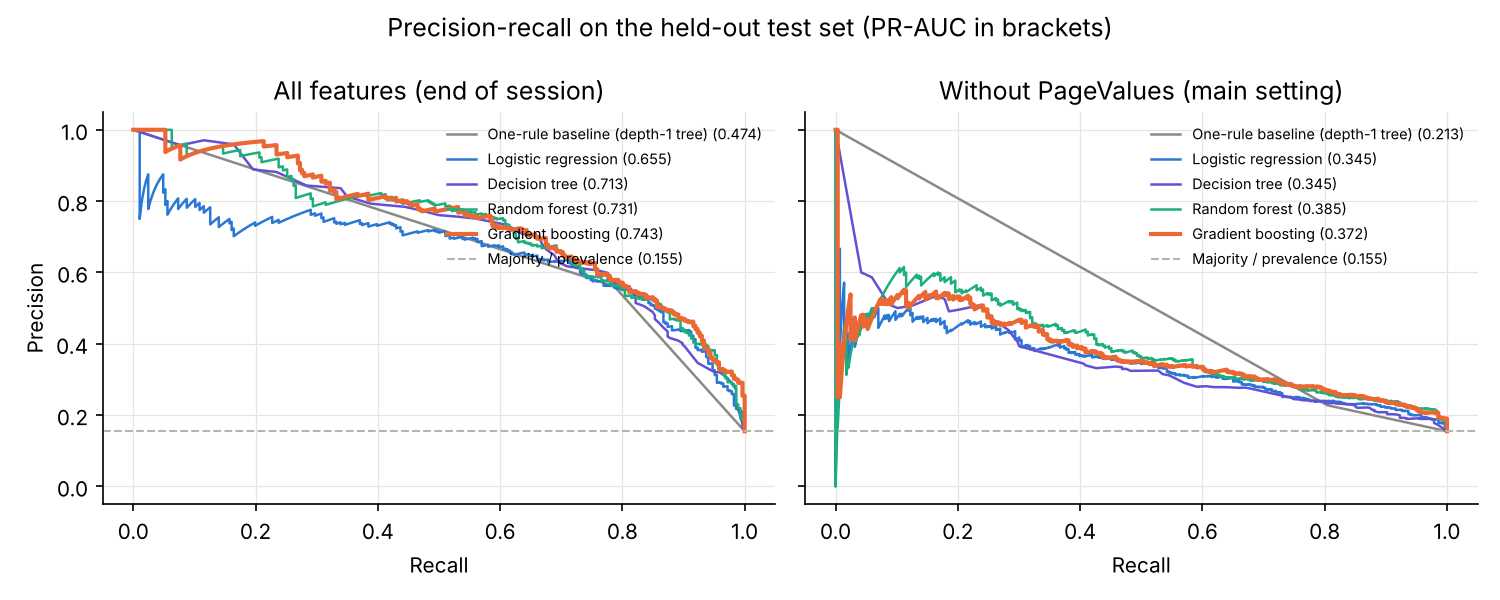

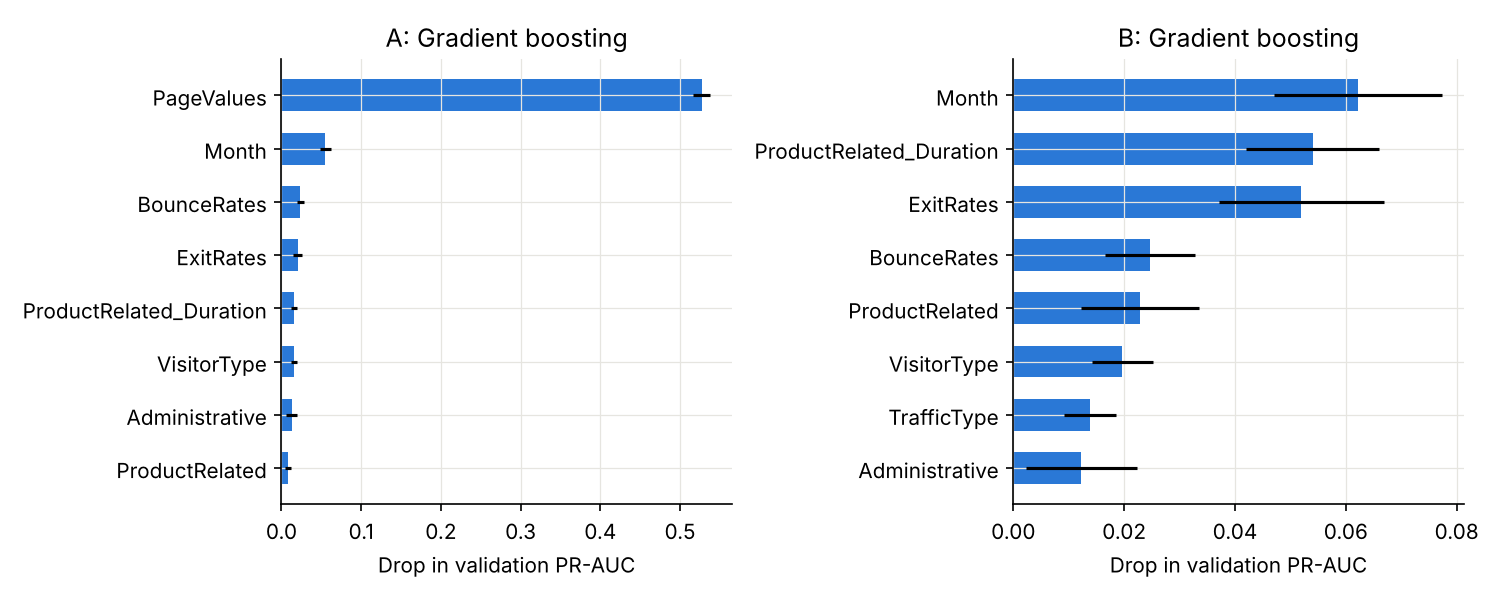

In [11]:
from IPython.display import Image, display
for f in ['pr_curves_test.png','permutation_importance.png']:
    display(Image(filename=str(ROOT/'results/figures'/f)))

## 8. Error analysis (selected model, setting B)

In [12]:
err = json.load(open(ROOT/'results/error_analysis.json'))
print(err['B']['counts'])
display(pd.DataFrame(err['B']['median_by_outcome']).T)
display(pd.DataFrame(err['B']['segments']['VisitorType']))
display(pd.DataFrame(err['B']['confident_fp'])); display(pd.DataFrame(err['B']['confident_fn']))

{'TP': 186, 'FP': 398, 'FN': 100, 'TN': 1166}


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
TP,3.0,54.625,0.0,0.0,37.0,1263.258,0.000,0.013,16.789,0.0
FN,2.0,46.500,0.0,0.0,21.0,682.324,0.005,0.023,13.794,0.0
FP,3.0,75.708,0.0,0.0,29.0,1178.154,0.000,0.015,0.000,0.0
TN,0.0,0.000,0.0,0.0,11.5,320.625,0.008,0.039,0.000,0.0


,segment,n,positives,recall,fp_rate,precision
0,New_Visitor,249,63,0.8095,0.4624,0.3723
1,Other,10,4,0.7500,0.5000,0.5000
2,Returning_Visitor,1591,219,0.6027,0.2252,0.2993


,row_id,p,Month,VisitorType,Weekend,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
0,12148,0.6618,Nov,Returning_Visitor,0.0,11.0,0.0,92.0,4637.538,0.001,0.011,17.284,0.0
1,7923,0.6470,Aug,New_Visitor,0.0,0.0,0.0,47.0,636.700,0.000,0.000,0.000,0.0
2,9576,0.6260,Nov,Returning_Visitor,0.0,7.0,4.0,337.0,11835.104,0.005,0.016,0.000,0.0
3,10301,0.6214,Nov,Returning_Visitor,0.0,3.0,5.0,272.0,7434.743,0.009,0.022,0.000,0.0


,row_id,p,Month,VisitorType,Weekend,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
0,10789,0.0237,Nov,Returning_Visitor,0.0,1.0,0.0,1.0,0.00,0.2,0.200,0.000,0.0
1,11798,0.0240,Nov,Returning_Visitor,0.0,0.0,0.0,6.0,81.75,0.0,0.067,0.000,0.0
2,9100,0.0267,Dec,Returning_Visitor,0.0,0.0,0.0,3.0,139.00,0.0,0.067,127.308,0.0
3,6449,0.0282,Oct,Returning_Visitor,0.0,0.0,0.0,4.0,236.80,0.0,0.050,36.261,0.0
